# Spectral Clustering and ST-GRSC

**Dubai Metro Station Profiling | CS F415 Data Mining**

Clustering of station-window ridership patterns using behavioural similarity and spatio-temporal graph structure.

## 1. Configuration and imports

In [2]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.linalg import eigh
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import connected_components
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

SEED = 42
K_PRIMARY = 6
ALPHA_PRIMARY = 0.70  # 1.0 = behaviour only; 0.0 = graph only
SIGMA_MULT_PRIMARY = 1.0
K_VALUES = list(range(2, 11))
SIGMA_MULTIPLIERS = [0.5, 1.0, 2.0]
ALPHA_VALUES = [0.45, 0.60, 0.70, 0.85, 1.00]
STABILITY_REPEATS = 100
STABILITY_STATION_FRACTION = 0.80
KMEANS_RESTARTS = 50
USE_S3 = True


def find_root():
    current = Path.cwd().resolve()
    for folder in [current, *current.parents]:
        if (folder / 'README.md').is_file() and (folder / 'notebooks').is_dir():
            return folder
    raise FileNotFoundError('Metro project root not found.')


ROOT = find_root()
FEATURES_FILE = ROOT / 'results/features/features.parquet'
EDGES_FILE = ROOT / 'reference/edges.csv'
HAND_LABELS_FILE = ROOT / 'results/hand_labels.csv'

KEY_COLUMNS = ['win', 'location_id', 'station']
AUX_COLUMNS = ['timed_taps', 'check_ins', 'check_outs']
WINDOW_ORDER = ['W17/18', 'W18/19', 'W19/20', 'W21/22', 'W24/25']

print('Repository:', ROOT)
print('Local features:', FEATURES_FILE.exists())
print('Station edges:', EDGES_FILE.exists())
print('Use S3:', USE_S3)

Repository: /Users/aryanchandra/Downloads/Metro-Spectral-STGRSC
Local features: True
Station edges: True
Use S3: True


## 2. Feature matrix

244 station-window observations and 17 standardized ridership features.

In [3]:
def canonical_id(value):
    """Stable station ID representation for both CSV and Parquet keys."""
    numeric = pd.to_numeric(pd.Series([value]), errors='coerce').iloc[0]
    if pd.notna(numeric) and float(numeric).is_integer():
        return str(int(numeric))
    return str(value).strip()


if USE_S3:
    import boto3
    import awswrangler as wr

    profile = os.environ.get('AWS_PROFILE') or None
    region = os.environ.get('AWS_REGION') or os.environ.get('AWS_DEFAULT_REGION') or 'ap-south-1'
    session = boto3.Session(profile_name=profile, region_name=region)
    bucket = os.environ.get('METRO_S3_BUCKET')
    if not bucket:
        # Resolve bucket without printing any account identifier.
        account = session.client('sts').get_caller_identity()['Account']
        bucket = f'dubai-metro-profiling-{account}'
    df = wr.s3.read_parquet(
        f's3://{bucket}/curated/features/', boto3_session=session
    )
else:
    if not FEATURES_FILE.exists():
        raise FileNotFoundError(f'Missing features: {FEATURES_FILE}')
    df = pd.read_parquet(FEATURES_FILE)

missing_columns = set(KEY_COLUMNS + AUX_COLUMNS) - set(df.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')

if df.duplicated(['win', 'location_id']).any():
    raise ValueError('The feature table contains duplicate station-window keys.')

feature_cols = [c for c in df.columns if c not in KEY_COLUMNS + AUX_COLUMNS]
if any(not pd.api.types.is_numeric_dtype(df[c]) for c in feature_cols):
    raise TypeError('Model features must all be numeric.')

df = df.sort_values(['win', 'location_id'], kind='stable').reset_index(drop=True)
df['station_key'] = df['location_id'].map(canonical_id)
X = df[feature_cols].to_numpy(dtype=np.float64)

assert X.shape == (244, 17), f'Expected (244,17), got {X.shape}'
assert np.isfinite(X).all(), 'Feature matrix contains non-finite values.'
assert df[['win', 'station_key']].duplicated().sum() == 0

node_keys = list(zip(df['win'].astype(str), df['station_key']))
node_to_idx = {key: i for i, key in enumerate(node_keys)}
assert len(node_to_idx) == len(node_keys)

print('Input table:', df.shape)
print('Model matrix:', X.shape)
print('Station IDs:', df['station_key'].nunique())
print('Windows:', df['win'].value_counts().reindex(WINDOW_ORDER).to_dict())
print('Feature means (max abs):', round(float(np.max(np.abs(X.mean(axis=0)))), 6))
print('Feature stds (range):', np.round([X.std(axis=0).min(), X.std(axis=0).max()], 6))
display(df[['win', 'location_id', 'station'] + feature_cols[:3]].head())

Input table: (244, 24)
Model matrix: (244, 17)
Station IDs: 53
Windows: {'W17/18': 47, 'W18/19': 45, 'W19/20': 46, 'W21/22': 53, 'W24/25': 53}
Feature means (max abs): 0.0
Feature stds (range): [1. 1.]


,win,location_id,station,check_in_share_00_07,check_in_share_07_10,check_in_share_10_16
0,W17/18,128,centrepoint,1.458880,1.107092,-0.005825
1,W17/18,129,Emirates,-0.806555,-0.988479,1.188134
2,W17/18,130,Airport Terminal 3,1.679147,0.411498,1.614566
3,W17/18,131,Airport Terminal 1,0.640393,-0.493969,1.222873
4,W17/18,132,GGICO,-1.571480,-1.012579,0.424582


## 3. Behavioural affinity

Gaussian RBF kernel; bandwidth determined by the median pairwise Euclidean distance.

Median bandwidth: 5.20666
Behavioural affinity: (244, 244)
Off-diagonal similarity range: 0.005499 to 0.993938


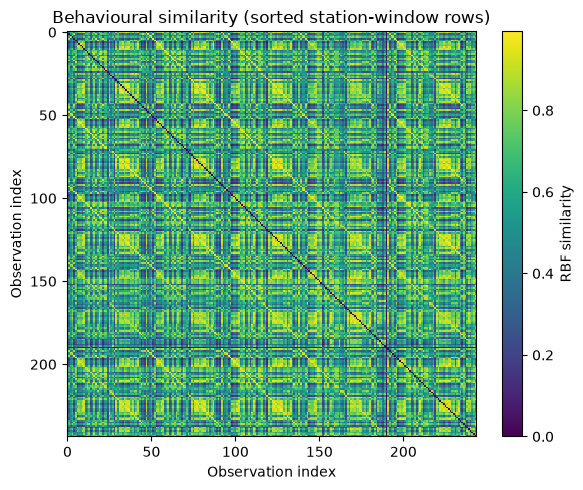

In [4]:
def rbf_affinity(data, sigma):
    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError('RBF bandwidth sigma must be positive and finite.')
    squared = squareform(pdist(data, metric='sqeuclidean'))
    affinity = np.exp(-squared / (2.0 * sigma**2))
    np.fill_diagonal(affinity, 0.0)
    return affinity


pairwise_distances = pdist(X, metric='euclidean')
SIGMA_BASE = float(np.median(pairwise_distances))
assert SIGMA_BASE > 0

S = rbf_affinity(X, SIGMA_BASE * SIGMA_MULT_PRIMARY)
assert S.shape == (244, 244)
assert np.allclose(S, S.T)
assert np.all(S >= 0)

print('Median bandwidth:', round(SIGMA_BASE, 6))
print('Behavioural affinity:', S.shape)
print('Off-diagonal similarity range:', round(float(S[S > 0].min()), 6),
      'to', round(float(S.max()), 6))

plt.figure(figsize=(6, 5))
plt.imshow(S, interpolation='nearest', aspect='auto')
plt.colorbar(label='RBF similarity')
plt.title('Behavioural similarity (sorted station-window rows)')
plt.xlabel('Observation index')
plt.ylabel('Observation index')
plt.tight_layout()
plt.show()

## 4. Spectral clustering

Symmetric normalized Laplacian, eigenvector embedding and K-Means.

In [5]:
def spectral_embedding(affinity):
    affinity = np.asarray(affinity, dtype=np.float64)
    if affinity.ndim != 2 or affinity.shape[0] != affinity.shape[1]:
        raise ValueError('Affinity must be square.')
    if not np.isfinite(affinity).all() or (affinity < 0).any():
        raise ValueError('Affinity must be finite and non-negative.')
    if not np.allclose(affinity, affinity.T, rtol=1e-9, atol=1e-12):
        raise ValueError('Affinity must be symmetric.')
    degrees = affinity.sum(axis=1)
    if np.any(degrees <= 0):
        raise ValueError('Isolated nodes detected. Use positive behavioural mixing or examine graph coverage.')

    inv_sqrt_degrees = 1.0 / np.sqrt(degrees)
    laplacian = np.eye(len(affinity)) - (
        inv_sqrt_degrees[:, None] * affinity * inv_sqrt_degrees[None, :]
    )
    laplacian = 0.5 * (laplacian + laplacian.T)
    eigenvalues, eigenvectors = eigh(laplacian, check_finite=True)
    return eigenvalues, eigenvectors


def spectral_labels(eigenvectors, k, seed=SEED):
    if not 2 <= k < eigenvectors.shape[0]:
        raise ValueError('k must be between 2 and number of nodes - 1.')
    embedding = eigenvectors[:, :k].copy()
    norms = np.linalg.norm(embedding, axis=1, keepdims=True)
    embedding /= np.maximum(norms, 1e-12)
    model = KMeans(n_clusters=k, random_state=seed, n_init=KMEANS_RESTARTS)
    return model.fit_predict(embedding), embedding


def spectral_fit(affinity, k=K_PRIMARY, seed=SEED):
    values, vectors = spectral_embedding(affinity)
    labels, embedded = spectral_labels(vectors, k, seed=seed)
    return labels, values, embedded


spectral_cluster, spectral_eigs, spectral_coords = spectral_fit(S)
print('Plain spectral clusters:', np.bincount(spectral_cluster))
print('First 10 Laplacian eigenvalues:', np.round(spectral_eigs[:10], 5))

Plain spectral clusters: [47 68 49 37 32 11]
First 10 Laplacian eigenvalues: [0.      0.72823 0.89336 0.93604 0.96498 0.97695 0.98086 0.98236 0.98686
 0.99043]


In [6]:
pairs = []

for i in range(len(df)):
    for j in range(i + 1, len(df)):
        if df.iloc[i]["win"] == df.iloc[j]["win"]:
            pairs.append({
                "Window": df.iloc[i]["win"],
                "Station 1": df.iloc[i]["station"],
                "Station 2": df.iloc[j]["station"],
                "Similarity": S[i, j],
                "Same cluster": spectral_cluster[i] == spectral_cluster[j]
            })

similar_pairs = pd.DataFrame(pairs)

display(
    similar_pairs
    .sort_values("Similarity", ascending=False)
    .head(15)
    .round(4)
)

,Window,Station 1,Station 2,Similarity,Same cluster
5312,W24/25,Mashreq,Dubai Airport Free Zone,0.9858,True
4368,W21/22,Salah Al Din,Sharaf DG,0.9829,True
5726,W24/25,Abu Baker Al Siddique,Salah Al Din,0.9816,True
978,W17/18,Al Nahda,Abu Hail,0.9784,True
4297,W21/22,Stadium,Salah Al Din,0.9780,False
3449,W21/22,Union,BurJuman,0.9770,False
5848,W24/25,The Gardens,Al Furjan,0.9769,True
2725,W19/20,Equiti,Dubai Healthcare City,0.9766,True
5258,W24/25,Equiti,Dubai Healthcare City,0.9764,True
3565,W21/22,ADCB,Salah Al Din,0.9761,True


### Scikit-learn consistency check

In [7]:
from sklearn.cluster import SpectralClustering

sklearn_spectral = SpectralClustering(
    n_clusters=K_PRIMARY,
    affinity='precomputed',
    assign_labels='kmeans',
    random_state=SEED,
    n_init=KMEANS_RESTARTS,
).fit_predict(S)

reference_ari = adjusted_rand_score(spectral_cluster, sklearn_spectral)
print('ARI: custom vs scikit-learn spectral:', round(float(reference_ari), 5))
print('Custom counts:', np.bincount(spectral_cluster))
print('Library counts:', np.bincount(sklearn_spectral))

ARI: custom vs scikit-learn spectral: 0.66968
Custom counts: [47 68 49 37 32 11]
Library counts: [74 11 42  6 77 34]


In [8]:
from sklearn.manifold import spectral_embedding as sklearn_embedding

rng = np.random.RandomState(SEED)

embedding = sklearn_embedding(
    S,
    n_components=K_PRIMARY,
    random_state=rng,
    drop_first=False
)

reproduced_labels = KMeans(
    n_clusters=K_PRIMARY,
    n_init=KMEANS_RESTARTS,
    random_state=rng
).fit_predict(embedding)

print(
    "Scikit-learn reproduction ARI:",
    adjusted_rand_score(sklearn_spectral, reproduced_labels)
)

Scikit-learn reproduction ARI: 1.0


## 5. Eigenvalue analysis and cluster-count sweep

Evaluate k = 2–10; use k = 6 for comparison with Ward.

,method,n,k,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,sse
0,spectral,244,2,109,135,0.3277,1.2259,140.7388,2622.7181
1,spectral,244,3,62,117,0.2825,1.3025,111.9792,2150.0162
2,spectral,244,4,49,71,0.2720,1.3222,106.3884,1780.3683
3,spectral,244,5,37,70,0.2462,1.5082,90.0547,1654.4407
4,spectral,244,6,11,68,0.2466,1.4431,77.7877,1574.6744
5,spectral,244,7,16,57,0.2160,1.6380,60.2224,1643.0217
6,spectral,244,8,14,44,0.1951,1.4787,69.8821,1349.9198
7,spectral,244,9,11,40,0.1929,1.5241,65.7336,1281.1405
8,spectral,244,10,10,35,0.2044,1.4352,65.9560,1172.8223


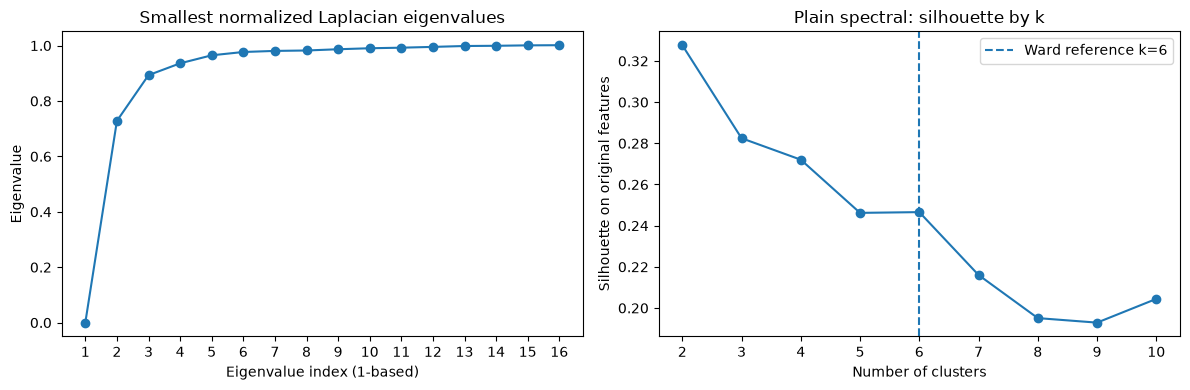

Largest displayed eigengap after eigenvalue #: 1
Primary comparison k: 6


In [9]:
def sse_score(data, labels):
    return float(sum(
        np.sum((data[labels == label] - data[labels == label].mean(axis=0))**2)
        for label in np.unique(labels)
    ))


def evaluate_clusters(data, labels, method, **parameters):
    labels = np.asarray(labels)
    unique_labels, counts = np.unique(labels, return_counts=True)
    valid = 2 <= len(unique_labels) < len(labels)
    result = dict(
        method=method,
        n=len(labels),
        k=int(len(unique_labels)),
        smallest_cluster=int(counts.min()),
        largest_cluster=int(counts.max()),
        silhouette=float(silhouette_score(data, labels)) if valid else np.nan,
        davies_bouldin=float(davies_bouldin_score(data, labels)) if valid else np.nan,
        calinski_harabasz=float(calinski_harabasz_score(data, labels)) if valid else np.nan,
        sse=sse_score(data, labels),
    )
    return {**result, **parameters}


spectral_k_rows = []
_, plain_eigenvectors = spectral_embedding(S)
for k in K_VALUES:
    labels, _ = spectral_labels(plain_eigenvectors, k)
    spectral_k_rows.append(evaluate_clusters(X, labels, 'spectral', k=k))
spectral_k_table = pd.DataFrame(spectral_k_rows)
display(spectral_k_table.round(4))

shown = min(16, len(spectral_eigs))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(1, shown + 1), spectral_eigs[:shown], marker='o')
axes[0].set_title('Smallest normalized Laplacian eigenvalues')
axes[0].set_xlabel('Eigenvalue index (1-based)')
axes[0].set_ylabel('Eigenvalue')
axes[0].set_xticks(np.arange(1, shown + 1))
axes[1].plot(spectral_k_table['k'], spectral_k_table['silhouette'], marker='o')
axes[1].axvline(K_PRIMARY, linestyle='--', label='Ward reference k=6')
axes[1].set_title('Plain spectral: silhouette by k')
axes[1].set_xlabel('Number of clusters')
axes[1].set_ylabel('Silhouette on original features')
axes[1].legend()
plt.tight_layout()
plt.show()

eigengaps = np.diff(spectral_eigs[:shown])
print('Largest displayed eigengap after eigenvalue #:', int(np.argmax(eigengaps) + 1))
print('Primary comparison k:', K_PRIMARY)

## 6. Spatial and temporal graph

Construct symmetric adjacency matrices aligned with station-window feature rows.

In [10]:
if not EDGES_FILE.exists():
    raise FileNotFoundError(
        f'Missing {EDGES_FILE}. Copy reference/edges.csv from the station-graph branch first.'
    )

edges = pd.read_csv(
    EDGES_FILE,
    dtype={'src_win': str, 'src_location_id': str,
           'dst_win': str, 'dst_location_id': str, 'kind': str}
)
required_edge_cols = {
    'src_win', 'src_location_id', 'dst_win', 'dst_location_id', 'kind', 'weight'
}
assert required_edge_cols.issubset(edges.columns), 'Edge columns do not match the expected schema.'
assert edges['kind'].isin(['spatial', 'temporal']).all()
assert np.isfinite(edges['weight'].astype(float)).all()
assert (edges['weight'].astype(float) > 0).all()


def graph_matrices(edge_data, lookup, n, uniform_temporal=False):
    spatial = np.zeros((n, n), dtype=float)
    temporal = np.zeros((n, n), dtype=float)
    duplicate_tracker = set()
    covered_nodes = set()

    for edge in edge_data.itertuples(index=False):
        u = (str(edge.src_win), canonical_id(edge.src_location_id))
        v = (str(edge.dst_win), canonical_id(edge.dst_location_id))
        if u not in lookup or v not in lookup:
            raise ValueError(f'Graph contains a node missing from features: {u}, {v}')
        i, j = lookup[u], lookup[v]
        if i == j:
            raise ValueError(f'Graph self-loop: {u}')
        kind = edge.kind
        signature = (min(i, j), max(i, j), kind)
        if signature in duplicate_tracker:
            raise ValueError(f'Duplicate graph edge: {signature}')
        duplicate_tracker.add(signature)
        weight = 1.0 if kind == 'temporal' and uniform_temporal else float(edge.weight)
        matrix = spatial if kind == 'spatial' else temporal
        matrix[i, j] = weight
        matrix[j, i] = weight
        covered_nodes.update((i, j))

    return spatial, temporal, covered_nodes


A_spatial, A_temporal, covered = graph_matrices(edges, node_to_idx, len(X))
assert covered == set(range(len(X))), 'Not all feature rows appear in edges.csv.'
assert np.allclose(A_spatial, A_spatial.T)
assert np.allclose(A_temporal, A_temporal.T)
assert not np.any(np.diag(A_spatial)) and not np.any(np.diag(A_temporal))

n_spatial = int(np.count_nonzero(np.triu(A_spatial, k=1)))
n_temporal = int(np.count_nonzero(np.triu(A_temporal, k=1)))
assert n_spatial == 244 and n_temporal == 191, 'Unexpected graph counts; review updated edge file.'

print('Spatial edges:', n_spatial)
print('Temporal edges:', n_temporal)
print('Node coverage:', len(covered), 'of', len(X))
for name, matrix in [('spatial', A_spatial), ('temporal', A_temporal),
                     ('combined', A_spatial + A_temporal)]:
    components, memberships = connected_components(matrix, directed=False)
    print(f'{name:>9} connected components: {components} '
          f'(isolated nodes: {int((matrix.sum(axis=1) == 0).sum())})')

Spatial edges: 244
Temporal edges: 191
Node coverage: 244 of 244
  spatial connected components: 5 (isolated nodes: 0)
 temporal connected components: 53 (isolated nodes: 0)
 combined connected components: 1 (isolated nodes: 0)


## 7. ST-GRSC

Combine normalized behavioural and graph affinities: `W = αS + (1 − α)A`. Spatial and temporal components receive equal total mass.

Primary alpha: 0.7
Plain spectral counts: [47 68 49 37 32 11]
ST-GRSC counts: [19 52 23 50 36 64]
Plain spectral silhouette: 0.24658
ST-GRSC silhouette: 0.04578


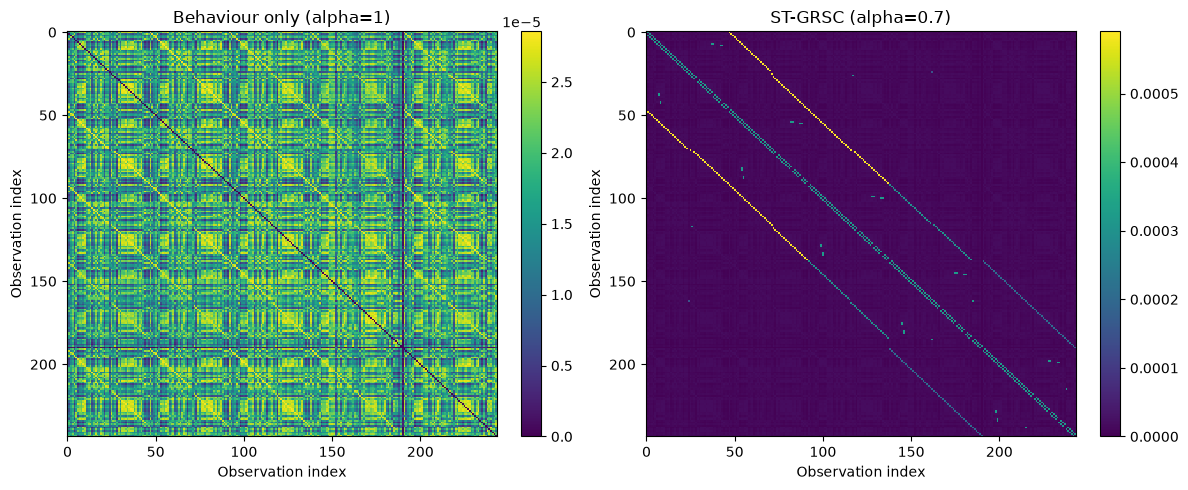

In [11]:
def normalize_mass(matrix):
    total = float(np.sum(matrix))
    if total <= 0:
        return np.zeros_like(matrix, dtype=float)
    return np.asarray(matrix, dtype=float) / total


def graph_affinity(spatial, temporal, mode='both'):
    if mode == 'none':
        return np.zeros_like(spatial, dtype=float)
    if mode == 'spatial':
        return normalize_mass(spatial)
    if mode == 'temporal':
        return normalize_mass(temporal)
    if mode != 'both':
        raise ValueError(f'Unknown graph mode: {mode}')
    parts = [normalize_mass(m) for m in (spatial, temporal) if np.sum(m) > 0]
    return sum(parts) / len(parts) if parts else np.zeros_like(spatial, dtype=float)


def mixed_affinity(behaviour, spatial, temporal, alpha, mode='both'):
    if not 0 <= alpha <= 1:
        raise ValueError('Alpha must lie between 0 and 1.')
    Sb = normalize_mass(behaviour)
    if mode == 'none':
        if alpha != 1.0:
            raise ValueError('No-graph ablation must use alpha=1.')
        return Sb
    A = graph_affinity(spatial, temporal, mode=mode)
    if (1 - alpha) > 0 and not np.any(A):
        raise ValueError(f'No edges available for requested mode: {mode}')
    W = alpha * Sb + (1.0 - alpha) * A
    np.fill_diagonal(W, 0.0)
    return W


W_spectral = mixed_affinity(S, A_spatial, A_temporal, alpha=1.0, mode='none')
W_stgrsc = mixed_affinity(S, A_spatial, A_temporal,
                          alpha=ALPHA_PRIMARY, mode='both')

stgrsc_cluster, stgrsc_eigs, stgrsc_coords = spectral_fit(W_stgrsc)
assert len(spectral_cluster) == len(stgrsc_cluster) == len(X)

print('Primary alpha:', ALPHA_PRIMARY)
print('Plain spectral counts:', np.bincount(spectral_cluster))
print('ST-GRSC counts:', np.bincount(stgrsc_cluster))
print('Plain spectral silhouette:', round(silhouette_score(X, spectral_cluster), 5))
print('ST-GRSC silhouette:', round(silhouette_score(X, stgrsc_cluster), 5))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, matrix, title in zip(
    axes, [W_spectral, W_stgrsc],
    ['Behaviour only (alpha=1)', f'ST-GRSC (alpha={ALPHA_PRIMARY})']
):
    image = ax.imshow(matrix, interpolation='nearest', aspect='auto')
    ax.set_title(title)
    ax.set_xlabel('Observation index')
    ax.set_ylabel('Observation index')
    fig.colorbar(image, ax=ax, fraction=0.045)
plt.tight_layout()
plt.show()

Primary alpha: 0.8
Plain spectral counts: [47 68 49 37 32 11]
ST-GRSC counts: [59 66 48 21 28 22]
Plain spectral silhouette: 0.24658
ST-GRSC silhouette: 0.07396


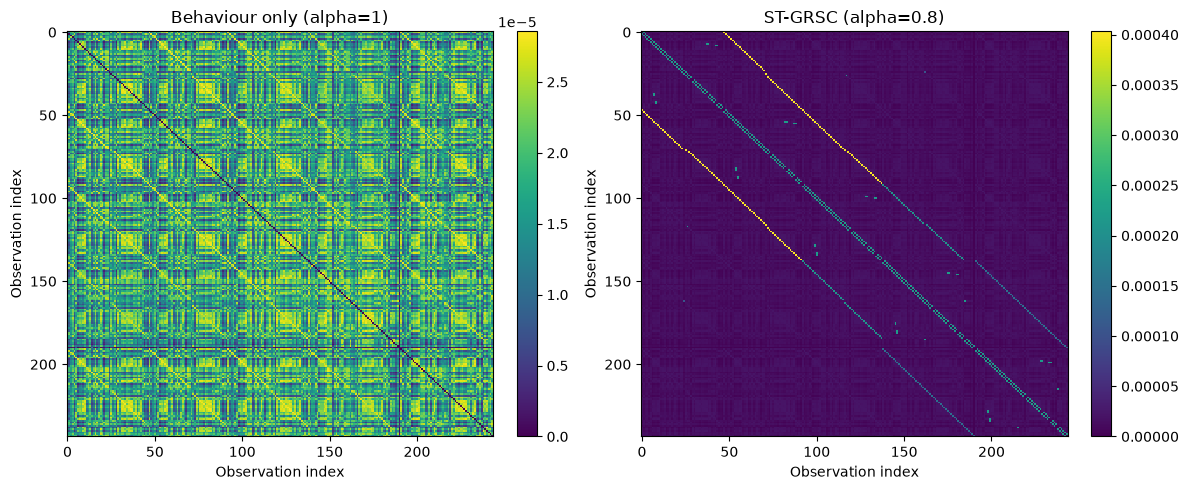

In [13]:
def normalize_mass(matrix):
    total = float(np.sum(matrix))
    if total <= 0:
        return np.zeros_like(matrix, dtype=float)
    return np.asarray(matrix, dtype=float) / total


def graph_affinity(spatial, temporal, mode='both'):
    if mode == 'none':
        return np.zeros_like(spatial, dtype=float)
    if mode == 'spatial':
        return normalize_mass(spatial)
    if mode == 'temporal':
        return normalize_mass(temporal)
    if mode != 'both':
        raise ValueError(f'Unknown graph mode: {mode}')
    parts = [normalize_mass(m) for m in (spatial, temporal) if np.sum(m) > 0]
    return sum(parts) / len(parts) if parts else np.zeros_like(spatial, dtype=float)


def mixed_affinity(behaviour, spatial, temporal, alpha, mode='both'):
    if not 0 <= alpha <= 1:
        raise ValueError('Alpha must lie between 0 and 1.')
    Sb = normalize_mass(behaviour)
    if mode == 'none':
        if alpha != 1.0:
            raise ValueError('No-graph ablation must use alpha=1.')
        return Sb
    A = graph_affinity(spatial, temporal, mode=mode)
    if (1 - alpha) > 0 and not np.any(A):
        raise ValueError(f'No edges available for requested mode: {mode}')
    W = alpha * Sb + (1.0 - alpha) * A
    np.fill_diagonal(W, 0.0)
    return W


W_spectral = mixed_affinity(S, A_spatial, A_temporal, alpha=1.0, mode='none')
ALPHA_PRIMARY = 0.80
W_stgrsc = mixed_affinity(S, A_spatial, A_temporal,
                          alpha=ALPHA_PRIMARY, mode='both')

stgrsc_cluster, stgrsc_eigs, stgrsc_coords = spectral_fit(W_stgrsc)
assert len(spectral_cluster) == len(stgrsc_cluster) == len(X)

print('Primary alpha:', ALPHA_PRIMARY)
print('Plain spectral counts:', np.bincount(spectral_cluster))
print('ST-GRSC counts:', np.bincount(stgrsc_cluster))
print('Plain spectral silhouette:', round(silhouette_score(X, spectral_cluster), 5))
print('ST-GRSC silhouette:', round(silhouette_score(X, stgrsc_cluster), 5))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, matrix, title in zip(
    axes, [W_spectral, W_stgrsc],
    ['Behaviour only (alpha=1)', f'ST-GRSC (alpha={ALPHA_PRIMARY})']
):
    image = ax.imshow(matrix, interpolation='nearest', aspect='auto')
    ax.set_title(title)
    ax.set_xlabel('Observation index')
    ax.set_ylabel('Observation index')
    fig.colorbar(image, ax=ax, fraction=0.045)
plt.tight_layout()
plt.show()

Primary alpha: 0.9
Plain spectral counts: [47 68 49 37 32 11]
ST-GRSC counts: [65 53 21 32 30 43]
Plain spectral silhouette: 0.24658
ST-GRSC silhouette: 0.11514


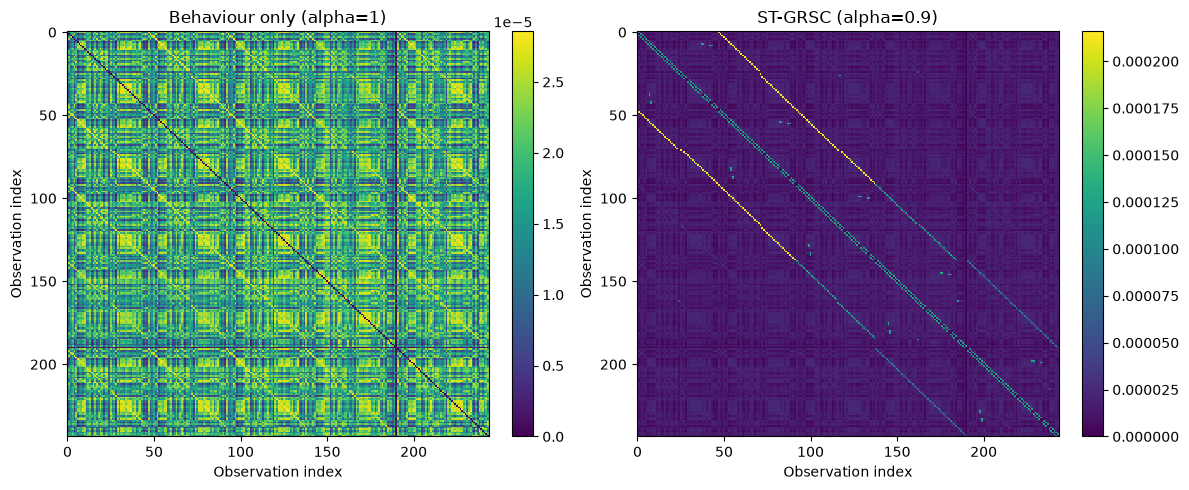

In [15]:
def normalize_mass(matrix):
    total = float(np.sum(matrix))
    if total <= 0:
        return np.zeros_like(matrix, dtype=float)
    return np.asarray(matrix, dtype=float) / total


def graph_affinity(spatial, temporal, mode='both'):
    if mode == 'none':
        return np.zeros_like(spatial, dtype=float)
    if mode == 'spatial':
        return normalize_mass(spatial)
    if mode == 'temporal':
        return normalize_mass(temporal)
    if mode != 'both':
        raise ValueError(f'Unknown graph mode: {mode}')
    parts = [normalize_mass(m) for m in (spatial, temporal) if np.sum(m) > 0]
    return sum(parts) / len(parts) if parts else np.zeros_like(spatial, dtype=float)


def mixed_affinity(behaviour, spatial, temporal, alpha, mode='both'):
    if not 0 <= alpha <= 1:
        raise ValueError('Alpha must lie between 0 and 1.')
    Sb = normalize_mass(behaviour)
    if mode == 'none':
        if alpha != 1.0:
            raise ValueError('No-graph ablation must use alpha=1.')
        return Sb
    A = graph_affinity(spatial, temporal, mode=mode)
    if (1 - alpha) > 0 and not np.any(A):
        raise ValueError(f'No edges available for requested mode: {mode}')
    W = alpha * Sb + (1.0 - alpha) * A
    np.fill_diagonal(W, 0.0)
    return W


W_spectral = mixed_affinity(S, A_spatial, A_temporal, alpha=1.0, mode='none')
ALPHA_PRIMARY = 0.90
W_stgrsc = mixed_affinity(S, A_spatial, A_temporal,
                          alpha=ALPHA_PRIMARY, mode='both')

stgrsc_cluster, stgrsc_eigs, stgrsc_coords = spectral_fit(W_stgrsc)
assert len(spectral_cluster) == len(stgrsc_cluster) == len(X)

print('Primary alpha:', ALPHA_PRIMARY)
print('Plain spectral counts:', np.bincount(spectral_cluster))
print('ST-GRSC counts:', np.bincount(stgrsc_cluster))
print('Plain spectral silhouette:', round(silhouette_score(X, spectral_cluster), 5))
print('ST-GRSC silhouette:', round(silhouette_score(X, stgrsc_cluster), 5))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, matrix, title in zip(
    axes, [W_spectral, W_stgrsc],
    ['Behaviour only (alpha=1)', f'ST-GRSC (alpha={ALPHA_PRIMARY})']
):
    image = ax.imshow(matrix, interpolation='nearest', aspect='auto')
    ax.set_title(title)
    ax.set_xlabel('Observation index')
    ax.set_ylabel('Observation index')
    fig.colorbar(image, ax=ax, fraction=0.045)
plt.tight_layout()
plt.show()

Primary alpha: 0.95
Plain spectral counts: [47 68 49 37 32 11]
ST-GRSC counts: [47 35 41 54 51 16]
Plain spectral silhouette: 0.24658
ST-GRSC silhouette: 0.19681


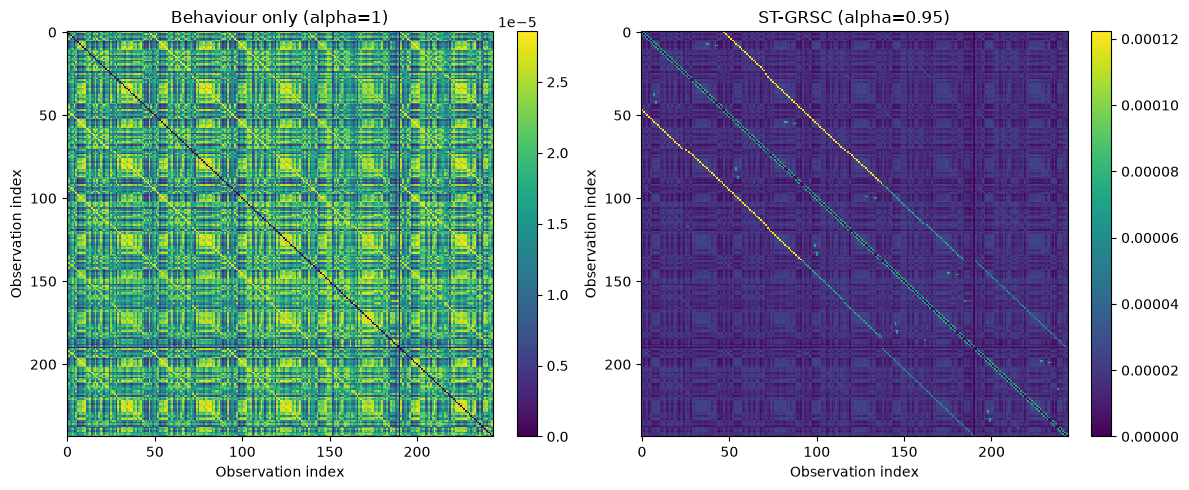

In [16]:
def normalize_mass(matrix):
    total = float(np.sum(matrix))
    if total <= 0:
        return np.zeros_like(matrix, dtype=float)
    return np.asarray(matrix, dtype=float) / total


def graph_affinity(spatial, temporal, mode='both'):
    if mode == 'none':
        return np.zeros_like(spatial, dtype=float)
    if mode == 'spatial':
        return normalize_mass(spatial)
    if mode == 'temporal':
        return normalize_mass(temporal)
    if mode != 'both':
        raise ValueError(f'Unknown graph mode: {mode}')
    parts = [normalize_mass(m) for m in (spatial, temporal) if np.sum(m) > 0]
    return sum(parts) / len(parts) if parts else np.zeros_like(spatial, dtype=float)


def mixed_affinity(behaviour, spatial, temporal, alpha, mode='both'):
    if not 0 <= alpha <= 1:
        raise ValueError('Alpha must lie between 0 and 1.')
    Sb = normalize_mass(behaviour)
    if mode == 'none':
        if alpha != 1.0:
            raise ValueError('No-graph ablation must use alpha=1.')
        return Sb
    A = graph_affinity(spatial, temporal, mode=mode)
    if (1 - alpha) > 0 and not np.any(A):
        raise ValueError(f'No edges available for requested mode: {mode}')
    W = alpha * Sb + (1.0 - alpha) * A
    np.fill_diagonal(W, 0.0)
    return W


W_spectral = mixed_affinity(S, A_spatial, A_temporal, alpha=1.0, mode='none')
ALPHA_PRIMARY = 0.95
W_stgrsc = mixed_affinity(S, A_spatial, A_temporal,
                          alpha=ALPHA_PRIMARY, mode='both')

stgrsc_cluster, stgrsc_eigs, stgrsc_coords = spectral_fit(W_stgrsc)
assert len(spectral_cluster) == len(stgrsc_cluster) == len(X)

print('Primary alpha:', ALPHA_PRIMARY)
print('Plain spectral counts:', np.bincount(spectral_cluster))
print('ST-GRSC counts:', np.bincount(stgrsc_cluster))
print('Plain spectral silhouette:', round(silhouette_score(X, spectral_cluster), 5))
print('ST-GRSC silhouette:', round(silhouette_score(X, stgrsc_cluster), 5))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, matrix, title in zip(
    axes, [W_spectral, W_stgrsc],
    ['Behaviour only (alpha=1)', f'ST-GRSC (alpha={ALPHA_PRIMARY})']
):
    image = ax.imshow(matrix, interpolation='nearest', aspect='auto')
    ax.set_title(title)
    ax.set_xlabel('Observation index')
    ax.set_ylabel('Observation index')
    fig.colorbar(image, ax=ax, fraction=0.045)
plt.tight_layout()
plt.show()

Primary alpha: 0.98
Plain spectral counts: [47 68 49 37 32 11]
ST-GRSC counts: [37 43 40 14 45 65]
Plain spectral silhouette: 0.24658
ST-GRSC silhouette: 0.23448


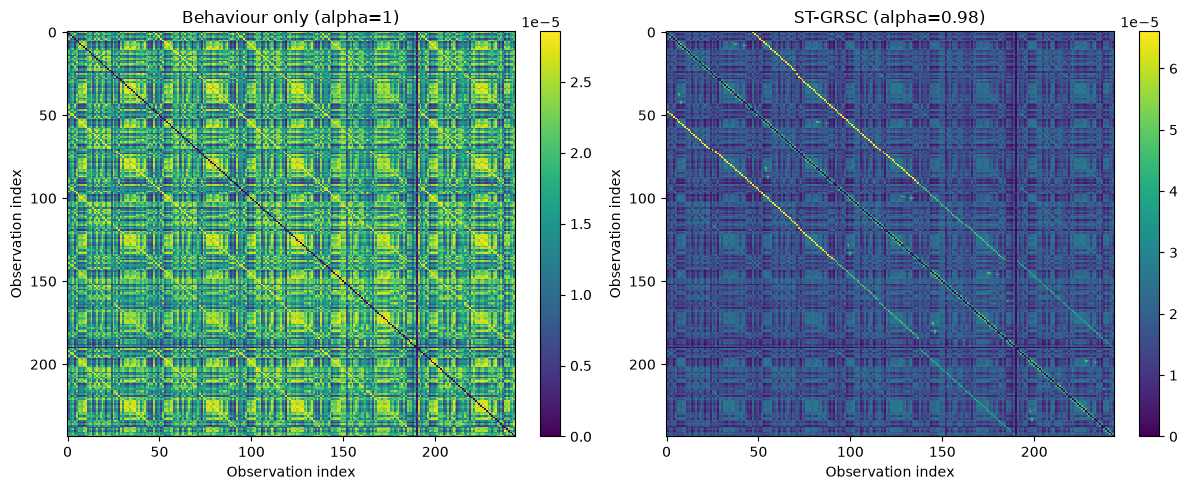

In [25]:
def normalize_mass(matrix):
    total = float(np.sum(matrix))
    if total <= 0:
        return np.zeros_like(matrix, dtype=float)
    return np.asarray(matrix, dtype=float) / total


def graph_affinity(spatial, temporal, mode='both'):
    if mode == 'none':
        return np.zeros_like(spatial, dtype=float)
    if mode == 'spatial':
        return normalize_mass(spatial)
    if mode == 'temporal':
        return normalize_mass(temporal)
    if mode != 'both':
        raise ValueError(f'Unknown graph mode: {mode}')
    parts = [normalize_mass(m) for m in (spatial, temporal) if np.sum(m) > 0]
    return sum(parts) / len(parts) if parts else np.zeros_like(spatial, dtype=float)


def mixed_affinity(behaviour, spatial, temporal, alpha, mode='both'):
    if not 0 <= alpha <= 1:
        raise ValueError('Alpha must lie between 0 and 1.')
    Sb = normalize_mass(behaviour)
    if mode == 'none':
        if alpha != 1.0:
            raise ValueError('No-graph ablation must use alpha=1.')
        return Sb
    A = graph_affinity(spatial, temporal, mode=mode)
    if (1 - alpha) > 0 and not np.any(A):
        raise ValueError(f'No edges available for requested mode: {mode}')
    W = alpha * Sb + (1.0 - alpha) * A
    np.fill_diagonal(W, 0.0)
    return W

W_spectral = mixed_affinity(S, A_spatial, A_temporal, alpha=1.0, mode='none')
ALPHA_PRIMARY = 0.98
W_stgrsc = mixed_affinity(S, A_spatial, A_temporal,
                          alpha=ALPHA_PRIMARY, mode='both')

stgrsc_cluster, stgrsc_eigs, stgrsc_coords = spectral_fit(W_stgrsc)
assert len(spectral_cluster) == len(stgrsc_cluster) == len(X)

print('Primary alpha:', ALPHA_PRIMARY)
print('Plain spectral counts:', np.bincount(spectral_cluster))
print('ST-GRSC counts:', np.bincount(stgrsc_cluster))
print('Plain spectral silhouette:', round(silhouette_score(X, spectral_cluster), 5))
print('ST-GRSC silhouette:', round(silhouette_score(X, stgrsc_cluster), 5))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, matrix, title in zip(
    axes, [W_spectral, W_stgrsc],
    ['Behaviour only (alpha=1)', f'ST-GRSC (alpha={ALPHA_PRIMARY})']
):
    image = ax.imshow(matrix, interpolation='nearest', aspect='auto')
    ax.set_title(title)
    ax.set_xlabel('Observation index')
    ax.set_ylabel('Observation index')
    fig.colorbar(image, ax=ax, fraction=0.045)
plt.tight_layout()
plt.show()

Primary alpha: 1.0
Plain spectral counts: [47 68 49 37 32 11]
ST-GRSC counts: [47 68 49 37 32 11]
Plain spectral silhouette: 0.24658
ST-GRSC silhouette: 0.24658


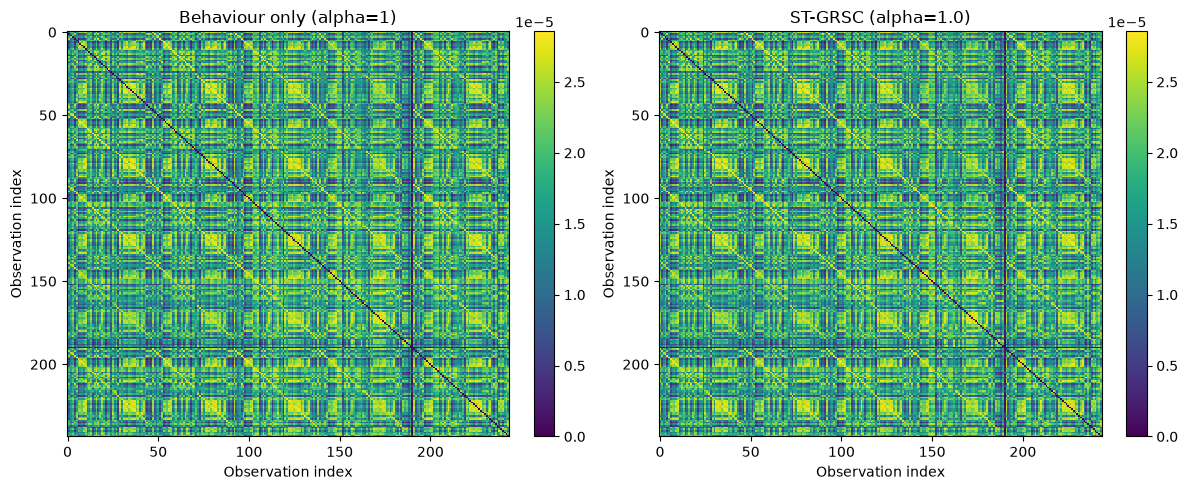

In [18]:
def normalize_mass(matrix):
    total = float(np.sum(matrix))
    if total <= 0:
        return np.zeros_like(matrix, dtype=float)
    return np.asarray(matrix, dtype=float) / total


def graph_affinity(spatial, temporal, mode='both'):
    if mode == 'none':
        return np.zeros_like(spatial, dtype=float)
    if mode == 'spatial':
        return normalize_mass(spatial)
    if mode == 'temporal':
        return normalize_mass(temporal)
    if mode != 'both':
        raise ValueError(f'Unknown graph mode: {mode}')
    parts = [normalize_mass(m) for m in (spatial, temporal) if np.sum(m) > 0]
    return sum(parts) / len(parts) if parts else np.zeros_like(spatial, dtype=float)


def mixed_affinity(behaviour, spatial, temporal, alpha, mode='both'):
    if not 0 <= alpha <= 1:
        raise ValueError('Alpha must lie between 0 and 1.')
    Sb = normalize_mass(behaviour)
    if mode == 'none':
        if alpha != 1.0:
            raise ValueError('No-graph ablation must use alpha=1.')
        return Sb
    A = graph_affinity(spatial, temporal, mode=mode)
    if (1 - alpha) > 0 and not np.any(A):
        raise ValueError(f'No edges available for requested mode: {mode}')
    W = alpha * Sb + (1.0 - alpha) * A
    np.fill_diagonal(W, 0.0)
    return W


W_spectral = mixed_affinity(S, A_spatial, A_temporal, alpha=1.0, mode='none')
ALPHA_PRIMARY = 1.0
W_stgrsc = mixed_affinity(S, A_spatial, A_temporal,
                          alpha=ALPHA_PRIMARY, mode='both')

stgrsc_cluster, stgrsc_eigs, stgrsc_coords = spectral_fit(W_stgrsc)
assert len(spectral_cluster) == len(stgrsc_cluster) == len(X)

print('Primary alpha:', ALPHA_PRIMARY)
print('Plain spectral counts:', np.bincount(spectral_cluster))
print('ST-GRSC counts:', np.bincount(stgrsc_cluster))
print('Plain spectral silhouette:', round(silhouette_score(X, spectral_cluster), 5))
print('ST-GRSC silhouette:', round(silhouette_score(X, stgrsc_cluster), 5))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, matrix, title in zip(
    axes, [W_spectral, W_stgrsc],
    ['Behaviour only (alpha=1)', f'ST-GRSC (alpha={ALPHA_PRIMARY})']
):
    image = ax.imshow(matrix, interpolation='nearest', aspect='auto')
    ax.set_title(title)
    ax.set_xlabel('Observation index')
    ax.set_ylabel('Observation index')
    fig.colorbar(image, ax=ax, fraction=0.045)
plt.tight_layout()
plt.show()

In [19]:
def edge_consistency(adjacency, labels):
    upper = np.triu(adjacency, k=1)
    same_cluster = labels[:, None] == labels[None, :]

    total_weight = upper.sum()
    if total_weight == 0:
        return np.nan

    return float(
        (upper * same_cluster).sum() / total_weight
    )


alpha_values = [0.95, 0.98, 0.99, 1.00]

results = []

for alpha in alpha_values:
    W = mixed_affinity(
        S, A_spatial, A_temporal,
        alpha=alpha,
        mode='both'
    )

    labels, _, _ = spectral_fit(W)

    results.append({
        'alpha': alpha,
        'silhouette': silhouette_score(X, labels),
        'spatial_consistency': edge_consistency(
            A_spatial, labels
        ),
        'temporal_consistency': edge_consistency(
            A_temporal, labels
        ),
        'ARI_vs_plain': adjusted_rand_score(
            spectral_cluster, labels
        )
    })

consistency_table = pd.DataFrame(results)

display(consistency_table.round(4))

,alpha,silhouette,spatial_consistency,temporal_consistency,ARI_vs_plain
0,0.95,0.1968,0.4713,0.8643,0.4570
1,0.98,0.2345,0.4139,0.8015,0.8003
2,0.99,0.2392,0.3852,0.8015,0.8486
3,1.00,0.2466,0.3361,0.8028,1.0000


## 8. Parameter sensitivity

Evaluate RBF bandwidth and graph mixing weight at k = 6.

,method,n,k,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,sse,alpha,sigma_mult,requested_k
0,stgrsc,244,6,20,65,0.0635,2.6728,29.2056,2570.7090,0.45,0.5,6
1,stgrsc,244,6,19,76,0.1252,2.3714,37.3326,2324.7246,0.60,0.5,6
2,stgrsc,244,6,14,81,0.1800,2.2573,43.8539,2158.9552,0.70,0.5,6
3,stgrsc,244,6,13,67,0.2254,1.6901,60.4439,1827.4503,0.85,0.5,6
4,spectral,244,6,7,62,0.2516,1.3239,85.8474,1479.5702,1.00,0.5,6
5,stgrsc,244,6,20,56,0.0119,3.4337,26.7021,2657.3254,0.45,1.0,6
6,stgrsc,244,6,20,56,0.0256,3.2333,29.1010,2574.2132,0.60,1.0,6
7,stgrsc,244,6,19,64,0.0458,2.9670,31.9852,2480.9247,0.70,1.0,6
8,stgrsc,244,6,21,65,0.1059,1.8341,45.5415,2119.8375,0.85,1.0,6
9,spectral,244,6,11,68,0.2466,1.4431,77.7877,1574.6744,1.00,1.0,6


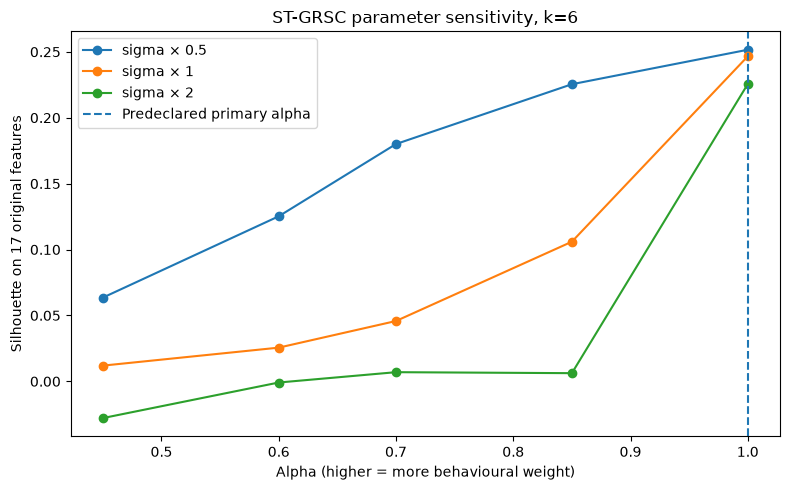

Top exploratory configurations by silhouette:


,method,n,k,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,sse,alpha,sigma_mult,requested_k
4,spectral,244,6,7,62,0.2516,1.3239,85.8474,1479.5702,1.00,0.5,6
9,spectral,244,6,11,68,0.2466,1.4431,77.7877,1574.6744,1.00,1.0,6
14,spectral,244,6,11,62,0.2255,1.4746,71.1219,1663.0867,1.00,2.0,6
3,stgrsc,244,6,13,67,0.2254,1.6901,60.4439,1827.4503,0.85,0.5,6
2,stgrsc,244,6,14,81,0.1800,2.2573,43.8539,2158.9552,0.70,0.5,6


In [20]:
sweep_rows = []
for sigma_mult in SIGMA_MULTIPLIERS:
    affinity = rbf_affinity(X, SIGMA_BASE * sigma_mult)
    for alpha in ALPHA_VALUES:
        W = mixed_affinity(affinity, A_spatial, A_temporal,
                           alpha=alpha, mode='both')
        labels, _, _ = spectral_fit(W)
        sweep_rows.append(evaluate_clusters(
            X, labels, 'spectral' if alpha == 1.0 else 'stgrsc',
            alpha=alpha, sigma_mult=sigma_mult, requested_k=K_PRIMARY
        ))

sweep_table = pd.DataFrame(sweep_rows)
display(sweep_table.sort_values(['sigma_mult', 'alpha']).round(4))

plt.figure(figsize=(8, 5))
for sigma_mult, part in sweep_table.groupby('sigma_mult', sort=True):
    part = part.sort_values('alpha')
    plt.plot(part['alpha'], part['silhouette'], marker='o',
             label=f'sigma × {sigma_mult:g}')
plt.axvline(ALPHA_PRIMARY, linestyle='--', label='Predeclared primary alpha')
plt.xlabel('Alpha (higher = more behavioural weight)')
plt.ylabel('Silhouette on 17 original features')
plt.title('ST-GRSC parameter sensitivity, k=6')
plt.legend()
plt.tight_layout()
plt.show()

print('Top exploratory configurations by silhouette:')
display(sweep_table.sort_values('silhouette', ascending=False).head(5).round(4))

,method,n,k,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,sse,alpha,requested_k
0,stgrsc,244,6,19,64,0.04578,2.96698,31.98517,2480.92465,0.70,6
1,stgrsc,244,6,21,66,0.07396,2.53143,36.95202,2335.18720,0.80,6
2,stgrsc,244,6,21,65,0.11514,1.90230,47.38383,2078.72020,0.90,6
3,stgrsc,244,6,16,54,0.19681,1.56504,64.56308,1760.33684,0.95,6
4,stgrsc,244,6,17,51,0.20357,1.52612,66.37317,1732.37970,0.97,6
5,stgrsc,244,6,14,65,0.23448,1.47223,74.08066,1622.64738,0.98,6
6,stgrsc,244,6,14,67,0.23916,1.49857,74.80878,1612.99545,0.99,6
7,spectral,244,6,11,68,0.24658,1.44310,77.78770,1574.67441,1.00,6


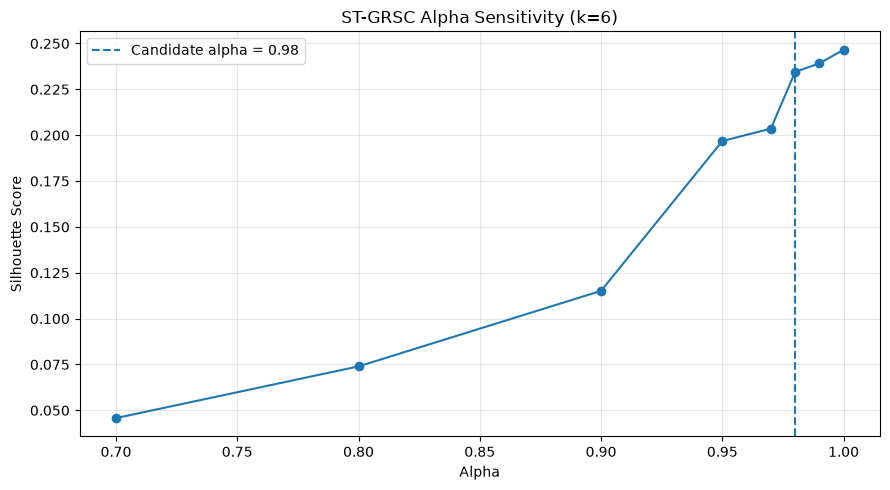

In [21]:
ALPHA_VALUES = [0.70, 0.80, 0.90, 0.95, 0.97, 0.98, 0.99, 1.00]

alpha_rows = []

for alpha in ALPHA_VALUES:
    W = mixed_affinity(
        S, A_spatial, A_temporal,
        alpha=alpha,
        mode='both'
    )

    labels, _, _ = spectral_fit(W)

    alpha_rows.append(evaluate_clusters(
        X, labels,
        'spectral' if alpha == 1.0 else 'stgrsc',
        alpha=alpha,
        requested_k=K_PRIMARY
    ))

alpha_table = pd.DataFrame(alpha_rows)

display(alpha_table.round(5))

plt.figure(figsize=(9, 5))
plt.plot(
    alpha_table['alpha'],
    alpha_table['silhouette'],
    marker='o'
)
plt.axvline(0.98, linestyle='--', label='Candidate alpha = 0.98')
plt.xlabel('Alpha')
plt.ylabel('Silhouette Score')
plt.title('ST-GRSC Alpha Sensitivity (k=6)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Ablation study

Behaviour only, spatial only, temporal only and combined graph.

,method,n,k,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,sse,graph_mode,alpha,sigma_mult,ari_vs_plain_spectral
0,No graph,244,6,11,68,0.2466,1.4431,77.7877,1574.6744,none,1.00,1.0,1.0000
1,Spatial only,244,6,18,50,0.1908,1.5702,65.1967,1750.4490,spatial,0.98,1.0,0.5052
2,Temporal only,244,6,11,72,0.2342,1.3864,75.8986,1598.7609,temporal,0.98,1.0,0.7784
3,Spatial + temporal,244,6,14,65,0.2345,1.4722,74.0807,1622.6474,both,0.98,1.0,0.8003


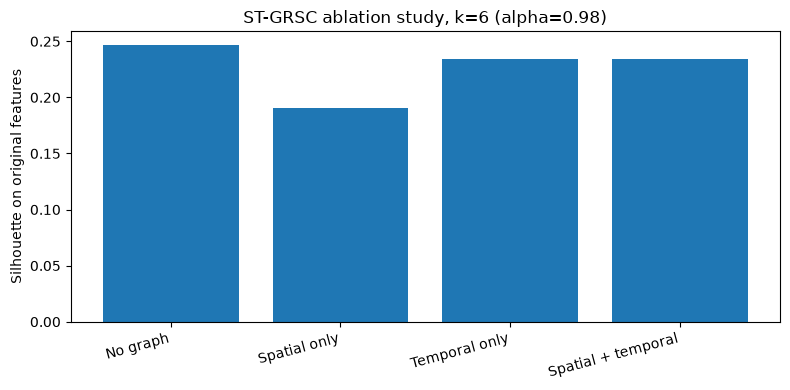

Graph-only diagnostic: {'method': 'graph_only', 'n': 244, 'k': 6, 'smallest_cluster': 12, 'largest_cluster': 65, 'silhouette': -0.052181322221644476, 'davies_bouldin': 3.7541046475091773, 'calinski_harabasz': 9.512687928780894, 'sse': 3457.1092196923432, 'alpha': 0.0}


In [23]:
ALPHA_PRIMARY = 0.98

ablation_settings = [
    ('No graph', 'none', 1.0),
    ('Spatial only', 'spatial', ALPHA_PRIMARY),
    ('Temporal only', 'temporal', ALPHA_PRIMARY),
    ('Spatial + temporal', 'both', ALPHA_PRIMARY),
]

ablation_rows = []
ablation_labels = {}

for title, mode, alpha in ablation_settings:
    W = mixed_affinity(S, A_spatial, A_temporal, alpha=alpha, mode=mode)
    labels, _, _ = spectral_fit(W)

    ablation_labels[title] = labels

    ablation_rows.append(evaluate_clusters(
        X, labels, title,
        graph_mode=mode,
        alpha=alpha,
        sigma_mult=SIGMA_MULT_PRIMARY,
        ari_vs_plain_spectral=float(
            adjusted_rand_score(spectral_cluster, labels)
        )
    ))

ablation_table = pd.DataFrame(ablation_rows)
display(ablation_table.round(4))

plt.figure(figsize=(8, 4))
plt.bar(ablation_table['method'], ablation_table['silhouette'])
plt.ylabel('Silhouette on original features')
plt.title('ST-GRSC ablation study, k=6 (alpha=0.98)')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

# Graph-only diagnostic (alpha=0)
W_graph_only = mixed_affinity(
    S, A_spatial, A_temporal,
    alpha=0.0,
    mode='both'
)

try:
    graph_only_labels, _, _ = spectral_fit(W_graph_only)

    print(
        'Graph-only diagnostic:',
        evaluate_clusters(
            X, graph_only_labels,
            'graph_only',
            alpha=0.0
        )
    )
except ValueError as exc:
    print('Graph-only diagnostic skipped:', exc)

## 10. Temporal edge weighting

Compare gap-decayed and uniform temporal weights.

In [26]:
ALPHA_PRIMARY = 0.98

_, A_temporal_uniform, _ = graph_matrices(
    edges, node_to_idx, len(X), uniform_temporal=True
)

weighting_rows = []

for name, temporal_matrix in [
    ('Gap-decayed', A_temporal),
    ('Uniform temporal weights', A_temporal_uniform),
]:
    W = mixed_affinity(
        S, A_spatial, temporal_matrix,
        alpha=ALPHA_PRIMARY,
        mode='both'
    )

    labels, _, _ = spectral_fit(W)

    weighting_rows.append(evaluate_clusters(
        X, labels, name,
        alpha=ALPHA_PRIMARY,
        ari_vs_gap_decayed=float(
            adjusted_rand_score(stgrsc_cluster, labels)
        )
    ))

weighting_table = pd.DataFrame(weighting_rows)
display(weighting_table.round(4))

,method,n,k,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,sse,alpha,ari_vs_gap_decayed
0,Gap-decayed,244,6,14,65,0.2345,1.4722,74.0807,1622.6474,0.98,1.0000
1,Uniform temporal weights,244,6,15,68,0.2378,1.5447,73.0724,1636.2049,0.98,0.9078


## 11. Model comparison

K-Means, Ward, DBSCAN, Spectral and ST-GRSC. Metrics are evaluated in the original standardized feature space; DBSCAN noise is excluded from its cluster metrics.

In [28]:
from sklearn.cluster import KMeans, AgglomerativeClustering


ALPHA_PRIMARY = 0.98
K_PRIMARY = 6


W_spectral = mixed_affinity(
    S, A_spatial, A_temporal,
    alpha=1.0,
    mode='none'
)

spectral_cluster, _, _ = spectral_fit(W_spectral)

# ST-GRSC
W_stgrsc = mixed_affinity(
    S, A_spatial, A_temporal,
    alpha=ALPHA_PRIMARY,
    mode='both'
)

stgrsc_cluster, stgrsc_eigs, stgrsc_coords = spectral_fit(W_stgrsc)


kmeans_cluster = KMeans(
    n_clusters=K_PRIMARY,
    n_init=KMEANS_RESTARTS,
    random_state=SEED
).fit_predict(X)


ward_cluster = AgglomerativeClustering(
    n_clusters=K_PRIMARY,
    linkage='ward'
).fit_predict(X)


model_labels = {
    'kmeans': kmeans_cluster,
    'ward': ward_cluster,
    'spectral': spectral_cluster,
    'stgrsc': stgrsc_cluster
}

comparison_rows = []

for method, labels in model_labels.items():
    result = evaluate_clusters(
        X, labels, method,
        coverage=1.0
    )

    result['ari_vs_ward'] = float(
        adjusted_rand_score(ward_cluster, labels)
    )

    comparison_rows.append(result)


dbscan_path = ROOT / 'results/labels/dbscan.parquet'

if dbscan_path.exists():
    db = pd.read_parquet(dbscan_path)

    required = {'win', 'location_id', 'cluster'}

    if required.issubset(db.columns):
        db = db.copy()
        db['station_key'] = db['location_id'].map(canonical_id)

        joined = df[['win', 'station_key']].merge(
            db[['win', 'station_key', 'cluster']],
            on=['win', 'station_key'],
            how='left',
            validate='one_to_one',
            sort=False
        )

        if joined['cluster'].notna().all() and len(joined) == len(X):
            db_labels = joined['cluster'].to_numpy(dtype=int)
            inlier_mask = db_labels != -1

            db_result = evaluate_clusters(
                X[inlier_mask],
                db_labels[inlier_mask],
                'dbscan',
                coverage=float(inlier_mask.mean()),
                noise=int((~inlier_mask).sum())
            )

            db_result['ari_vs_ward'] = float(
                adjusted_rand_score(
                    ward_cluster[inlier_mask],
                    db_labels[inlier_mask]
                )
            )

            comparison_rows.append(db_result)

        else:
            print('DBSCAN label keys do not cover all rows.')

    else:
        print('DBSCAN labels missing required columns.')

else:
    print('DBSCAN label file not found.')


comparison_table = pd.DataFrame(comparison_rows)

display(comparison_table.round(4))

print('Primary alpha:', ALPHA_PRIMARY)
print('Number of clusters:', K_PRIMARY)
print('Total observations:', len(X))

,method,n,k,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,sse,coverage,ari_vs_ward,noise
0,kmeans,244,6,6,72,0.2696,1.3129,90.8593,1426.0136,1.0000,0.6642,NaN
1,ward,244,6,6,83,0.2785,1.3151,81.7876,1525.9942,1.0000,1.0000,NaN
2,spectral,244,6,11,68,0.2466,1.4431,77.7877,1574.6744,1.0000,0.4857,NaN
3,stgrsc,244,6,14,65,0.2345,1.4722,74.0807,1622.6474,1.0000,0.5139,NaN
4,dbscan,211,2,7,204,0.2814,0.8670,19.2554,2896.4766,0.8648,0.0226,33.0


Primary alpha: 0.98
Number of clusters: 6
Total observations: 244


In [44]:
import numpy as np
import pandas as pd
from pathlib import Path

def normalized_cut(W, labels):
    W = np.asarray(W, dtype=float)
    labels = np.asarray(labels).ravel()

    if W.shape != (len(labels), len(labels)):
        raise ValueError("Affinity matrix and labels have different sizes")

    degrees = W.sum(axis=1)
    score = 0.0

    for cluster in np.unique(labels):
        mask = labels == cluster
        volume = degrees[mask].sum()

        if volume <= 0:
            return np.nan

        score += W[np.ix_(mask, ~mask)].sum() / volume

    return float(score)


def find_labels(variable_names, file_names):
    for name in variable_names:
        if name in globals():
            return np.asarray(globals()[name]).ravel(), name

    for filename in file_names:
        path = Path(filename)

        if not path.exists():
            continue

        df = pd.read_parquet(path)

        for column in ["cluster", "cluster_label", "label", "labels"]:
            if column in df.columns:
                return df[column].to_numpy(), str(path)

    return None, None


methods = {
    "K-Means": (
        ["kmeans_labels", "labels_kmeans", "kmeans_cluster"],
        ["results/labels/kmeans.parquet"]
    ),
    "Ward": (
        ["ward_labels", "labels_ward", "ward_cluster"],
        ["results/labels/ward.parquet"]
    ),
    "DBSCAN": (
        ["dbscan_labels", "labels_dbscan", "dbscan_cluster"],
        ["results/labels/dbscan.parquet"]
    ),
    "Plain Spectral": (
        ["spectral_cluster"],
        ["results/labels/spectral.parquet"]
    ),
    "ST-GRSC": (
        ["stgrsc_cluster"],
        ["results/labels/stgrsc.parquet"]
    )
}

rows = []
missing = []

n = np.asarray(W_spectral).shape[0]

for method, (variable_names, file_names) in methods.items():

    labels, source = find_labels(variable_names, file_names)

    if labels is None:
        missing.append(f"{method}: labels not found")
        continue

    if len(labels) != n:
        missing.append(
            f"{method}: {len(labels)} labels, expected {n}"
        )
        continue

    clusters = len(set(labels) - {-1})
    noise = int(np.sum(labels == -1))

    rows.append({
        "Method": method,
        "Clusters": clusters,
        "Noise Points": noise,
        "Ncut (Behaviour)": normalized_cut(W_spectral, labels),
        "Ncut (ST-GRSC Graph)": normalized_cut(W_stgrsc, labels)
    })

ncut_comparison = pd.DataFrame(rows)

display(ncut_comparison.round(4))

if missing:
    print("\nMethods requiring labels:")
    for item in missing:
        print("-", item)

print("\nNote: DBSCAN noise (-1) is treated as a separate partition.")

,Method,Ncut (Behaviour),Ncut (ST-GRSC Graph)
0,Plain Spectral,4.6577,4.6156
1,ST-GRSC,4.6668,4.6192


NameError: name 'kmeans_labels' is not defined

NameError: name 'kmeans_labels' is not defined

## 12. Station-grouped stability

100 resamples of 80% of station IDs, with induced subgraphs for graph-based methods. ARI is computed against the corresponding full-data assignments.

,method,mean,std,min,max
0,spectral,0.7314,0.1233,0.4469,0.9650
1,stgrsc,0.6749,0.1172,0.4493,0.9225


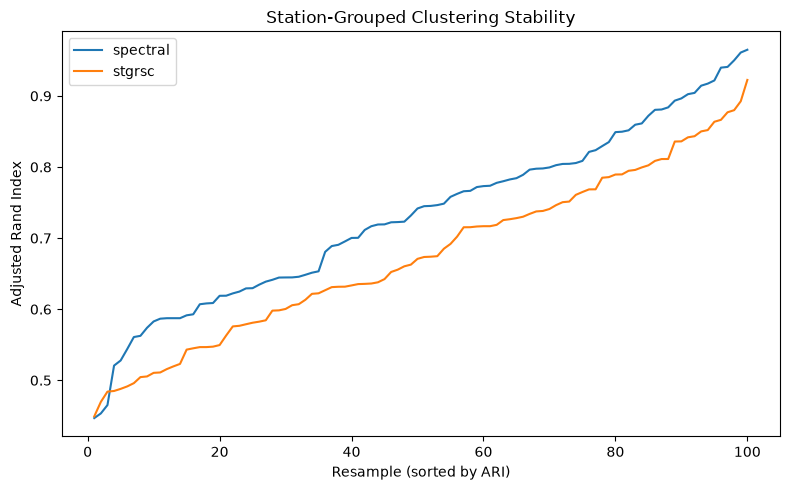

Resamples: 100
Stations per resample: 42
Primary alpha: 0.98
Clusters: 6


In [29]:
# Station-grouped stability analysis

ALPHA_PRIMARY = 0.98
N_RESAMPLES = 100
SAMPLE_FRACTION = 0.80

rng = np.random.default_rng(SEED)

stations = np.sort(df['station_key'].unique())
n_sample = int(round(len(stations) * SAMPLE_FRACTION))

# Full-data reference labels
plain_reference, _, _ = spectral_fit(
    mixed_affinity(S, A_spatial, A_temporal, alpha=1.0, mode='none')
)

stgrsc_reference, _, _ = spectral_fit(
    mixed_affinity(
        S, A_spatial, A_temporal,
        alpha=ALPHA_PRIMARY, mode='both'
    )
)

stability_rows = []

for run in range(N_RESAMPLES):

    selected_stations = rng.choice(
        stations, size=n_sample, replace=False
    )

    idx = np.flatnonzero(
        df['station_key'].isin(selected_stations).to_numpy()
    )

    # Induced feature similarity and graph matrices
    S_sub = S[np.ix_(idx, idx)]
    A_spatial_sub = A_spatial[np.ix_(idx, idx)]
    A_temporal_sub = A_temporal[np.ix_(idx, idx)]

    # Plain Spectral
    W_plain_sub = mixed_affinity(
        S_sub, A_spatial_sub, A_temporal_sub,
        alpha=1.0, mode='none'
    )

    plain_labels, _, _ = spectral_fit(W_plain_sub)

    # ST-GRSC
    W_stgrsc_sub = mixed_affinity(
        S_sub, A_spatial_sub, A_temporal_sub,
        alpha=ALPHA_PRIMARY, mode='both'
    )

    stgrsc_labels, _, _ = spectral_fit(W_stgrsc_sub)

    stability_rows.extend([
        {
            'run': run + 1,
            'method': 'spectral',
            'n_stations': len(selected_stations),
            'n_observations': len(idx),
            'ari': adjusted_rand_score(
                plain_reference[idx], plain_labels
            )
        },
        {
            'run': run + 1,
            'method': 'stgrsc',
            'n_stations': len(selected_stations),
            'n_observations': len(idx),
            'ari': adjusted_rand_score(
                stgrsc_reference[idx], stgrsc_labels
            )
        }
    ])

stability_table = pd.DataFrame(stability_rows)

stability_summary = (
    stability_table.groupby('method')['ari']
    .agg(['mean', 'std', 'min', 'max'])
    .reset_index()
)

display(stability_summary.round(4))

plt.figure(figsize=(8, 5))

for method, group in stability_table.groupby('method'):
    sorted_ari = np.sort(group['ari'].to_numpy())

    plt.plot(
        np.arange(1, len(sorted_ari) + 1),
        sorted_ari,
        label=method
    )

plt.xlabel('Resample (sorted by ARI)')
plt.ylabel('Adjusted Rand Index')
plt.title('Station-Grouped Clustering Stability')
plt.legend()
plt.tight_layout()
plt.show()

print('Resamples:', N_RESAMPLES)
print('Stations per resample:', n_sample)
print('Primary alpha:', ALPHA_PRIMARY)
print('Clusters:', K_PRIMARY)

In [30]:
display(stability_summary.round(4))

,method,mean,std,min,max
0,spectral,0.7314,0.1233,0.4469,0.9650
1,stgrsc,0.6749,0.1172,0.4493,0.9225


## 13. Station-level changes

Cluster assignments across the five observation windows.

In [33]:
ALPHA_PRIMARY = 0.98
def result_labels(method, clusters, alpha, sigma_mult=SIGMA_MULT_PRIMARY):
    table = df[['win', 'location_id', 'station', 'station_key']].copy()
    table['method'] = method
    table['k'] = K_PRIMARY
    table['alpha'] = float(alpha)
    table['sigma_mult'] = float(sigma_mult)
    table['cluster'] = np.asarray(clusters, dtype=int)
    return table


spectral_table = result_labels('spectral', spectral_cluster, 1.0)
stgrsc_table = result_labels('stgrsc', stgrsc_cluster, ALPHA_PRIMARY)


def transition_summary(assignments):
    output_rows = []
    for station_key, part in assignments.groupby('station_key', sort=True):
        part = part.copy()
        part['sort_order'] = pd.Categorical(
            part['win'], categories=WINDOW_ORDER, ordered=True
        )
        part = part.sort_values('sort_order')
        clusters = part['cluster'].to_numpy(dtype=int)
        output_rows.append({
            'station_key': station_key,
            'station': part['station'].iloc[-1],
            'windows_observed': len(part),
            'transitions_observed': max(0, len(part) - 1),
            'changes': int(np.count_nonzero(np.diff(clusters))) if len(clusters) > 1 else 0,
            'sequence': ' → '.join(f'{w}:C{c}' for w, c in zip(part['win'], clusters))
        })
    return pd.DataFrame(output_rows)


drift_spectral = transition_summary(spectral_table)
drift_stgrsc = transition_summary(stgrsc_table)
drift_summary = drift_spectral[['station_key', 'station', 'windows_observed',
                               'transitions_observed', 'changes', 'sequence']].rename(
    columns={'changes': 'spectral_changes', 'sequence': 'spectral_sequence'}
).merge(
    drift_stgrsc[['station_key', 'changes', 'sequence']].rename(
        columns={'changes': 'stgrsc_changes', 'sequence': 'stgrsc_sequence'}
    ), on='station_key', validate='one_to_one'
)
drift_summary['change_delta'] = (
    drift_summary['stgrsc_changes'] - drift_summary['spectral_changes']
)

print('Observed transitions (plain spectral):', drift_summary['spectral_changes'].sum())
print('Observed transitions (ST-GRSC):', drift_summary['stgrsc_changes'].sum())
display(drift_summary.sort_values(['change_delta', 'station']).head(15))

expo = drift_summary[drift_summary['station'].str.contains('expo', case=False, na=False)]
if len(expo):
    print('EXPO station-window history:')
    display(expo)
else:
    print('EXPO not found in the station names; inspect by station ID if renamed.')

Observed transitions (plain spectral): 44
Observed transitions (ST-GRSC): 46


,station_key,station,windows_observed,transitions_observed,spectral_changes,spectral_sequence,stgrsc_changes,stgrsc_sequence,change_delta
12,140,Emirates Towers,5,4,3,W17/18:C4 → W18/19:C4 → W19/20:C0 → W21/22:C2 ...,0,W17/18:C1 → W18/19:C1 → W19/20:C1 → W21/22:C1 ...,-3
7,135,Union,5,4,2,W17/18:C1 → W18/19:C1 → W19/20:C1 → W21/22:C3 ...,0,W17/18:C5 → W18/19:C5 → W19/20:C5 → W21/22:C5 ...,-2
40,172,Al Ras,5,4,2,W17/18:C4 → W18/19:C4 → W19/20:C4 → W21/22:C3 ...,1,W17/18:C1 → W18/19:C1 → W19/20:C1 → W21/22:C2 ...,-1
9,137,ADCB,5,4,0,W17/18:C1 → W18/19:C1 → W19/20:C1 → W21/22:C1 ...,0,W17/18:C5 → W18/19:C5 → W19/20:C5 → W21/22:C5 ...,0
36,167,Abu Baker Al Siddique,5,4,0,W17/18:C1 → W18/19:C1 → W19/20:C1 → W21/22:C1 ...,0,W17/18:C5 → W18/19:C5 → W19/20:C5 → W21/22:C5 ...,0
35,166,Abu Hail,5,4,2,W17/18:C1 → W18/19:C1 → W19/20:C1 → W21/22:C2 ...,2,W17/18:C5 → W18/19:C5 → W19/20:C5 → W21/22:C0 ...,0
3,131,Airport Terminal 1,5,4,0,W17/18:C5 → W18/19:C5 → W19/20:C5 → W21/22:C5 ...,0,W17/18:C3 → W18/19:C3 → W19/20:C3 → W21/22:C3 ...,0
2,130,Airport Terminal 3,5,4,0,W17/18:C5 → W18/19:C5 → W19/20:C5 → W21/22:C5 ...,0,W17/18:C3 → W18/19:C3 → W19/20:C3 → W21/22:C3 ...,0
49,183,Al Furjan,2,1,1,W21/22:C2 → W24/25:C1,1,W21/22:C0 → W24/25:C5,0
41,173,Al Ghubaiba,5,4,0,W17/18:C3 → W18/19:C3 → W19/20:C3 → W21/22:C3 ...,0,W17/18:C2 → W18/19:C2 → W19/20:C2 → W21/22:C2 ...,0


EXPO station-window history:


,station_key,station,windows_observed,transitions_observed,spectral_changes,spectral_sequence,stgrsc_changes,stgrsc_sequence,change_delta
52,187,EXPO,2,1,1,W21/22:C3 → W24/25:C0,1,W21/22:C2 → W24/25:C4,0


## 14. Hand-label comparison

Contextual validation using 12 independently annotated stations.

In [34]:
if HAND_LABELS_FILE.exists():
    hand = pd.read_csv(HAND_LABELS_FILE)
    required_hand = {'location_id', 'expected_type'}
    if not required_hand.issubset(hand.columns):
        raise ValueError('Hand labels file is missing location_id or expected_type.')
    hand['station_key'] = hand['location_id'].map(canonical_id)
    if hand['station_key'].duplicated().any():
        raise ValueError('Validation labels must contain one record per physical station.')

    checks = pd.concat([spectral_table, stgrsc_table], ignore_index=True).merge(
        hand[['station_key', 'expected_type']],
        on='station_key', how='inner', validate='many_to_one'
    )
    print('Hand-labelled physical stations represented:', checks['station_key'].nunique())
    display(pd.crosstab(
        [checks['method'], checks['expected_type']], checks['cluster']
    ))
    hand_check_table = checks[[
        'method', 'win', 'location_id', 'station', 'expected_type',
        'k', 'alpha', 'cluster'
    ]].sort_values(['method', 'expected_type', 'station', 'win'])
    display(hand_check_table.head(20))
else:
    hand_check_table = pd.DataFrame()
    print('Hand labels not found; qualitative check skipped.')

Hand-labelled physical stations represented: 12


cluster                        0  1  2  3  4  5
method   expected_type                         
spectral Airport               0  0  0  0  0  5
         Business              5  0  2  0  3  0
         Education             0  0  4  0  1  0
         Mixed                 3  5  0  1  1  0
         Residential           0  4  1  0  0  0
         Shopping and leisure  1  1  0  9  1  0
         Transfer and hub      0  5  0  5  0  0
stgrsc   Airport               0  0  0  5  0  0
         Business              2  3  0  0  5  0
         Education             1  3  1  0  0  0
         Mixed                 0  1  1  0  3  5
         Residential           1  0  0  0  0  4
         Shopping and leisure  0  1  9  0  1  1
         Transfer and hub      0  0  5  0  0  5

,method,win,location_id,station,expected_type,k,alpha,cluster
0,spectral,W17/18,130,Airport Terminal 3,Airport,6,1.0,5
11,spectral,W18/19,130,Airport Terminal 3,Airport,6,1.0,5
22,spectral,W19/20,130,Airport Terminal 3,Airport,6,1.0,5
33,spectral,W21/22,130,Airport Terminal 3,Airport,6,1.0,5
45,spectral,W24/25,130,Airport Terminal 3,Airport,6,1.0,5
10,spectral,W17/18,177,Dubai Healthcare City,Business,6,1.0,0
21,spectral,W18/19,177,Dubai Healthcare City,Business,6,1.0,0
32,spectral,W19/20,177,Dubai Healthcare City,Business,6,1.0,0
43,spectral,W21/22,177,Dubai Healthcare City,Business,6,1.0,0
55,spectral,W24/25,177,Dubai Healthcare City,Business,6,1.0,0


In [35]:
display(
    hand_check_table[
        hand_check_table['method'] == 'stgrsc'
    ].head(20)
)

,method,win,location_id,station,expected_type,k,alpha,cluster
57,stgrsc,W17/18,130,Airport Terminal 3,Airport,6,0.98,3
68,stgrsc,W18/19,130,Airport Terminal 3,Airport,6,0.98,3
79,stgrsc,W19/20,130,Airport Terminal 3,Airport,6,0.98,3
90,stgrsc,W21/22,130,Airport Terminal 3,Airport,6,0.98,3
102,stgrsc,W24/25,130,Airport Terminal 3,Airport,6,0.98,3
67,stgrsc,W17/18,177,Dubai Healthcare City,Business,6,0.98,4
78,stgrsc,W18/19,177,Dubai Healthcare City,Business,6,0.98,4
89,stgrsc,W19/20,177,Dubai Healthcare City,Business,6,0.98,4
100,stgrsc,W21/22,177,Dubai Healthcare City,Business,6,0.98,4
112,stgrsc,W24/25,177,Dubai Healthcare City,Business,6,0.98,4


## 15. Cluster profiles

Mean standardized features, cluster sizes and station-window assignments.

In [36]:
def cluster_profile(labels):
    profile_input = pd.DataFrame(X, columns=feature_cols)
    profile_input.insert(0, 'cluster', np.asarray(labels, dtype=int))
    profile = profile_input.groupby('cluster', sort=True)[feature_cols].mean().reset_index()
    sizes = pd.Series(labels).value_counts().rename_axis('cluster').reset_index(name='n_rows')
    return profile.merge(sizes, on='cluster', validate='one_to_one')


def station_window_matrix(assignments):
    return (assignments.pivot(index=['station_key', 'station'], columns='win', values='cluster')
            .reindex(columns=WINDOW_ORDER).reset_index())


spectral_profiles = cluster_profile(spectral_cluster)
stgrsc_profiles = cluster_profile(stgrsc_cluster)
spectral_station_windows = station_window_matrix(spectral_table)
stgrsc_station_windows = station_window_matrix(stgrsc_table)

print('Plain spectral mean feature z-scores:')
display(spectral_profiles.round(3))
print('ST-GRSC mean feature z-scores:')
display(stgrsc_profiles.round(3))
print('ST-GRSC station/window assignment preview:')
display(stgrsc_station_windows.head(10))

Plain spectral mean feature z-scores:


,cluster,check_in_share_00_07,check_in_share_07_10,check_in_share_10_16,check_in_share_16_20,check_in_share_20_24,check_out_share_00_07,check_out_share_07_10,check_out_share_10_16,check_out_share_16_20,check_out_share_20_24,net_flow_00_07,net_flow_07_10,net_flow_10_16,net_flow_16_20,net_flow_20_24,weekend_share,volume_share,n_rows
0,0,-1.002,-1.043,-0.915,1.572,-0.378,0.806,1.677,-0.144,-1.462,-1.256,-1.272,-1.328,-0.189,1.555,0.978,-0.998,-0.537,47
1,1,1.170,1.271,-0.032,-0.978,-0.412,-0.611,-0.795,-0.594,1.019,0.752,1.124,1.113,0.322,-1.051,-0.845,-0.000,0.569,68
2,2,-0.282,-0.025,0.783,-0.040,-0.326,0.197,-0.203,-0.472,0.066,0.516,-0.428,0.064,0.734,-0.083,-0.556,0.572,-0.470,49
3,3,-0.533,-0.669,-0.567,-0.061,1.630,-0.591,-0.489,1.082,0.384,-0.177,0.062,-0.207,-1.386,-0.250,0.779,1.112,0.653,37
4,4,-0.440,-0.339,0.652,0.167,-0.118,-0.516,0.249,0.960,-0.287,-0.553,0.180,-0.415,-0.321,0.261,0.275,-0.679,-0.162,32
5,5,1.379,-0.054,0.633,-0.775,0.474,2.946,-0.429,-0.045,-0.806,0.624,-0.341,0.409,1.141,0.302,0.098,-0.044,-0.852,11


ST-GRSC mean feature z-scores:


,cluster,check_in_share_00_07,check_in_share_07_10,check_in_share_10_16,check_in_share_16_20,check_in_share_20_24,check_out_share_00_07,check_out_share_07_10,check_out_share_10_16,check_out_share_16_20,check_out_share_20_24,net_flow_00_07,net_flow_07_10,net_flow_10_16,net_flow_16_20,net_flow_20_24,weekend_share,volume_share,n_rows
0,0,-0.208,0.088,0.844,-0.144,-0.364,0.217,-0.423,-0.618,0.187,0.834,-0.399,0.268,0.821,-0.231,-0.811,0.787,-0.584,37
1,1,-0.321,-0.192,0.565,0.132,-0.242,-0.354,0.222,0.602,-0.227,-0.390,0.085,-0.311,-0.099,0.213,0.100,-0.566,-0.147,43
2,2,-0.565,-0.663,-0.491,-0.058,1.576,-0.612,-0.449,1.105,0.364,-0.228,0.078,-0.231,-1.323,-0.229,0.814,1.070,0.534,40
3,3,0.965,-0.254,0.688,-0.378,0.157,2.725,0.035,-0.010,-1.035,0.179,-0.523,0.044,1.077,0.605,0.241,-0.421,-0.828,14
4,4,-1.052,-1.047,-0.965,1.579,-0.331,0.750,1.663,-0.168,-1.423,-1.241,-1.307,-1.328,-0.213,1.527,0.986,-0.928,-0.559,45
5,5,1.199,1.264,-0.033,-0.981,-0.407,-0.619,-0.789,-0.607,1.028,0.744,1.141,1.105,0.328,-1.057,-0.839,0.001,0.666,65


ST-GRSC station/window assignment preview:


win,station_key,station,W17/18,W18/19,W19/20,W21/22,W24/25
0,128,centrepoint,5.0,5.0,5.0,0.0,5.0
1,129,Emirates,3.0,3.0,3.0,4.0,4.0
2,130,Airport Terminal 3,3.0,3.0,3.0,3.0,3.0
3,131,Airport Terminal 1,3.0,3.0,3.0,3.0,3.0
4,132,GGICO,4.0,4.0,4.0,4.0,4.0
5,133,City Centre Deira,2.0,2.0,2.0,2.0,2.0
6,134,Al Rigga,5.0,5.0,5.0,5.0,5.0
7,135,Union,5.0,5.0,5.0,5.0,5.0
8,136,BurJuman,5.0,5.0,5.0,5.0,5.0
9,137,ADCB,5.0,5.0,5.0,5.0,5.0


In [37]:
station_members = (
    stgrsc_table
    .groupby(['cluster', 'station'])
    .size()
    .reset_index(name='windows_in_cluster')
    .sort_values(
        ['cluster', 'windows_in_cluster', 'station'],
        ascending=[True, False, True]
    )
)

for cluster in sorted(stgrsc_table['cluster'].unique()):
    print(f'\nCluster {cluster} — Representative stations')
    display(
        station_members[
            station_members['cluster'] == cluster
        ].head(10)
    )


Cluster 0 — Representative stations


,cluster,station,windows_in_cluster
5,0,Danube,5
11,0,Etisalat,3
15,0,Mashreq,3
2,0,Al Jadaf,2
6,0,Discovery Gardens,2
8,0,Dubai Internet City,2
9,0,Dubai Investment Park,2
10,0,Energy,2
12,0,Financial Centre,2
14,0,Jumeirah Golf Estates,2



Cluster 1 — Representative stations


,cluster,station,windows_in_cluster
23,1,Al Qusais,5
28,1,Emirates Towers,5
37,1,World Trade Centre,5
34,1,ONPASSIVE,4
22,1,Al Qiyadah,3
24,1,Al Ras,3
27,1,Dubai Internet City,3
30,1,Financial Centre,3
35,1,Oud Metha,3
29,1,Etisalat,2



Cluster 2 — Representative stations


,cluster,station,windows_in_cluster
38,2,Al Ghubaiba,5
41,2,Burj Khalifa/ Dubai Mall,5
42,2,City Centre Deira,5
48,2,Mall of the Emirates,5
40,2,Baniyas Square,4
46,2,Gold Souq,3
47,2,Ibn Battuta,3
50,2,Sobha Realty,3
39,2,Al Ras,2
45,2,Energy,2


... (2 outputs left out)


Cluster 4 — Representative stations


,cluster,station,windows_in_cluster
56,4,Al Khail,5
57,4,Business Bay,5
58,4,Creek,5
60,4,Dubai Healthcare City,5
63,4,Equiti,5
64,4,GGICO,5
66,4,UAE Exchange,5
55,4,Al Jadaf,3
59,4,DMCC,3
62,4,Emirates,2



Cluster 5 — Representative stations


,cluster,station,windows_in_cluster
67,5,ADCB,5
68,5,Abu Baker Al Siddique,5
73,5,Al Rigga,5
74,5,BurJuman,5
79,5,Salah Al Din,5
80,5,Sharaf DG,5
83,5,Union,5
69,5,Abu Hail,4
71,5,Al Nahda,4
75,5,Dubai Airport Free Zone,4



## Final Proposed ST-GRSC Cluster Names

**α = 0.98 | k = 6 | 244 station-window observations**

| Cluster | Proposed Name | Key Supporting Stations | Observations |
|---|---|---|---:|
| **C0** | Daytime & Weekend-Oriented | Danube, Etisalat, Mashreq | 37 |
| **C1** | Weekday Activity Centres | Emirates Towers, World Trade Centre, Al Qusais | 43 |
| **C2** | Shopping & Leisure Destinations | Dubai Mall, Mall of the Emirates, City Centre Deira | 40 |
| **C3** | Airport-Oriented Stations | Airport Terminal 1, Airport Terminal 3, Emirates | 14 |
| **C4** | Commuter Destinations | Business Bay, Dubai Healthcare City, Al Khail | 45 |
| **C5** | Commuter Origins & Interchanges | Union, BurJuman, ADCB, Al Rigga | 65 |
| **Total** | | | **244** |

*Cluster names are provisional behavioural interpretations based on standardized ridership features and representative station assignments.*

## 16. kNN affinity sensitivity

Compare dense RBF affinity with a symmetric 10-nearest-neighbour graph.

In [40]:
def symmetric_knn_affinity(similarity, neighbours=10):
    n = len(similarity)

    if not 1 <= neighbours < n:
        raise ValueError('neighbours must be in [1, n-1].')

    scores = np.asarray(similarity, dtype=float).copy()
    np.fill_diagonal(scores, -np.inf)

    keep = np.zeros_like(similarity)

    selected = np.argpartition(
        scores, -neighbours, axis=1
    )[:, -neighbours:]

    row_ids = np.arange(n)[:, None]
    keep[row_ids, selected] = similarity[row_ids, selected]

    keep = np.maximum(keep, keep.T)
    np.fill_diagonal(keep, 0.0)

    return keep


# kNN affinity
S_knn = symmetric_knn_affinity(S, neighbours=10)

# Plain Spectral (alpha = 1.0)
knn_spectral_W = mixed_affinity(
    S_knn, A_spatial, A_temporal,
    alpha=1.0, mode='none'
)

# ST-GRSC (alpha = 0.98)
knn_stgrsc_W = mixed_affinity(
    S_knn, A_spatial, A_temporal,
    alpha=ALPHA_PRIMARY, mode='both'
)

# Fit both models
knn_spectral_labels, _, _ = spectral_fit(knn_spectral_W)
knn_stgrsc_labels, _, _ = spectral_fit(knn_stgrsc_W)

# Evaluate
spectral_result = evaluate_clusters(
    X, knn_spectral_labels, 'spectral_knn10'
)

spectral_result['ari_vs_dense'] = adjusted_rand_score(
    spectral_cluster, knn_spectral_labels
)

stgrsc_result = evaluate_clusters(
    X, knn_stgrsc_labels, 'stgrsc_knn10'
)

stgrsc_result['ari_vs_dense'] = adjusted_rand_score(
    stgrsc_cluster, knn_stgrsc_labels
)

knn_sensitivity = pd.DataFrame([
    spectral_result,
    stgrsc_result
])

display(knn_sensitivity.round(4))

print('Primary alpha:', ALPHA_PRIMARY)
print('kNN neighbours:', 10)
print('Clusters:', K_PRIMARY)

,method,n,k,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,sse,ari_vs_dense
0,spectral_knn10,244,6,25,51,0.2089,1.4661,84.8563,1490.6410,0.4787
1,stgrsc_knn10,244,6,25,50,0.2119,1.4540,85.1635,1487.1923,0.5013


Primary alpha: 0.98
kNN neighbours: 10
Clusters: 6


## 17. Results and figures

In [41]:

ALPHA_PRIMARY = 0.98
K_PRIMARY = 6

labels_dir = ROOT / 'results/labels'
metrics_dir = ROOT / 'results/metrics'
figures_dir = ROOT / 'figures'

for path in (labels_dir, metrics_dir, figures_dir):
    path.mkdir(parents=True, exist_ok=True)

assert len(spectral_cluster) == len(X) == len(stgrsc_cluster)
assert np.allclose(stgrsc_table['alpha'], ALPHA_PRIMARY)
assert np.all(stgrsc_table['k'] == K_PRIMARY)
assert np.array_equal(stgrsc_table['cluster'], stgrsc_cluster)
assert np.array_equal(spectral_table['cluster'], spectral_cluster)

label_fields = [
    'win', 'location_id', 'station',
    'method', 'k', 'alpha', 'sigma_mult', 'cluster'
]

spectral_table[label_fields].to_parquet(
    labels_dir / 'spectral.parquet',
    index=False
)

stgrsc_table[label_fields].to_parquet(
    labels_dir / 'stgrsc.parquet',
    index=False
)

exports = {
    'spectral_k_sweep.csv': spectral_k_table,
    'stgrsc_alpha_sigma_sweep.csv': sweep_table,
    'stgrsc_ablation.csv': ablation_table,
    'stgrsc_temporal_weighting.csv': weighting_table,
    'spectral_stgrsc_model_comparison.csv': comparison_table,
    'spectral_stgrsc_stability.csv': stability_summary,
    'spectral_stgrsc_stability_repeats.csv': stability_table,
    'spectral_stgrsc_station_drift.csv': drift_summary,
    'spectral_stgrsc_hand_labels.csv': hand_check_table,
    'spectral_stgrsc_knn_sensitivity.csv': knn_sensitivity,
    'spectral_cluster_profiles.csv': spectral_profiles,
    'stgrsc_cluster_profiles.csv': stgrsc_profiles,
    'spectral_station_windows.csv': spectral_station_windows,
    'stgrsc_station_windows.csv': stgrsc_station_windows,
}

for filename, table in exports.items():
    table.to_csv(metrics_dir / filename, index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, 16), spectral_eigs[:15], marker='o')
ax.set(
    title='Spectral Laplacian Eigenvalues',
    xlabel='Eigenvalue Index',
    ylabel='Eigenvalue'
)
fig.tight_layout()
fig.savefig(figures_dir / 'spectral_eigenvalues.png', dpi=180)
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    spectral_k_table['k'],
    spectral_k_table['silhouette'],
    marker='o'
)
ax.axvline(K_PRIMARY, linestyle='--')
ax.set(
    title='Spectral Cluster-Count Sweep',
    xlabel='Number of Clusters (k)',
    ylabel='Silhouette Score'
)
fig.tight_layout()
fig.savefig(figures_dir / 'spectral_k_sweep.png', dpi=180)
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4))

for sigma_mult, part in sweep_table.groupby('sigma_mult'):
    part = part.sort_values('alpha')
    ax.plot(
        part['alpha'],
        part['silhouette'],
        marker='o',
        label=f'sigma × {sigma_mult:g}'
    )

ax.axvline(ALPHA_PRIMARY, linestyle='--')
ax.set(
    title='ST-GRSC Alpha / Sigma Sensitivity',
    xlabel='Alpha',
    ylabel='Silhouette on Original Features'
)
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / 'stgrsc_alpha_sigma_sweep.png', dpi=180)
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    ablation_table['method'],
    ablation_table['silhouette']
)
ax.set(
    title='ST-GRSC Ablation Study',
    ylabel='Silhouette on Original Features'
)
ax.tick_params(axis='x', labelrotation=15)
fig.tight_layout()
fig.savefig(figures_dir / 'stgrsc_ablation.png', dpi=180)
plt.close(fig)

print('Export completed successfully!')
print('Primary alpha:', ALPHA_PRIMARY)
print('Number of clusters:', K_PRIMARY)
print('Total observations:', len(X))
print('Parquet label files:', 2)
print('CSV result files:', len(exports))
print('PNG figures:', 4)
print('Total exported files:', 2 + len(exports) + 4)
print('All exports saved locally to:', ROOT)
print('Review results before committing; do not stage provisional reference files.')


Export completed successfully!
Primary alpha: 0.98
Number of clusters: 6
Total observations: 244
Parquet label files: 2
CSV result files: 14
PNG figures: 4
Total exported files: 20
All exports saved locally to: /Users/aryanchandra/Downloads/Metro-Spectral-STGRSC
Review results before committing; do not stage provisional reference files.
